# <a id='toc1_'></a>[Catálogo de terremotos](#toc0_)

**Sumário**<a id='toc0_'></a>    
- [Catálogo de terremotos](#toc1_)    
  - [Introdução](#toc1_1_)    
  - [Desenvolvimento](#toc1_2_)    
  - [Conclusão](#toc1_3_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

## <a id='toc1_1_'></a>[Introdução](#toc0_)

Agora, vamos unir as ferramentas construídas para conseguir capturar os dados dos terremotos que podem ter influenciado uma determinada distorção do feixe.

## <a id='toc1_2_'></a>[Desenvolvimento](#toc0_)

Vamos começar utilizando o `Client` do **obspy** para conseguir capturar os dados do catálogo de terremotos da USP. Vamos testar buscando terremotos relacionados ao evento do dia 9 de outubro, no Panamá.

In [6]:
from obspy.clients.fdsn import Client
import obspy.core.utcdatetime as utc

catalog = "USP"
client = Client(catalog)
events = client.get_events(
    starttime=utc.UTCDateTime("2026-10-09T00:00:00.000000Z"),
    endtime=utc.UTCDateTime("2026-10-09T23:59:00.000000Z"),
    minmagnitude=5.0,
)

events

9 Event(s) in Catalog:
2026-10-09T23:12:38.857356Z |  +7.033,  -80.011 | 5.41 mb | manual
2026-10-09T20:25:39.395890Z |  +7.671,  -81.305 | 6.30 mb | manual
2026-10-09T20:21:41.592678Z |  +7.146,  -80.154 | 5.12 mb | manual
2026-10-09T19:48:56.323765Z |  +7.531,  -81.143 | 5.29 mb | manual
2026-10-09T19:46:01.019697Z |  +7.275,  -79.673 | 5.15 mb | manual
2026-10-09T18:37:46.196386Z |  +7.353,  -80.436 | 6.05 mb | manual
2026-10-09T18:22:16.278310Z |  +7.487,  -80.217 | 5.25 mb | manual
2026-10-09T17:56:07.118061Z |  +7.194,  -81.319 | 7.67 mB | manual
2026-10-09T10:22:08.548996Z | -20.339,  -68.578 | 5.30 mb | manual

Podemos ver que o catálogo nos entrega diferentes pontos de início para o terremoto. Agora podemos aplicar os métodos de análise das ondas para montar uma tabela contendo todas as informações necessárias para continuarmos.

In [15]:
import os
import pandas as pd
from obspy.core.event.catalog import Catalog
from obspy import taup
from module import arrival_list, earth_plot, calculate_GDM52_arrival_times

SIRIUS_LOCATION = (-22.807606, -47.052526)
POS_LAT_SIRIUS, POS_LON_SIRIUS = SIRIUS_LOCATION

def load_dataframe():
    """
    Load the saved data in .csv format and output a dataframe with the earthquakes

    Output:

    - an existing dataframe of the events or an empty dataframe with the correct number of columns


    - an existing dataframe of the phase arrival or an empty dataframe with the correct number of columns
    """

    if os.path.exists("Data/time_data.csv") and os.path.exists("Data/event_data.csv"):
        timeframe = pd.read_csv("Data/time_data.csv", sep=";")
        eventframe = pd.read_csv("Data/event_data.csv", sep=";")
    else:
        eventframe = None
        timeframe = None

    return eventframe, timeframe

def table_create(
    latitude: float,
    longitude: float,
    depth: float,
    magnitude: float,
    magnitude_type: str,
    event_id: str,
    arrivals: taup.tau.Arrivals,
    UTC_origin: utc.UTCDateTime,
    model_name: str,
    catalog: str,
    epicenter_distance: float,
    event_data: pd.DataFrame = None,
    time_data: pd.DataFrame = None,
):
    """
    Function that add or create a Data Frame in pandas format for the event and it's waves.

    Entry:

    - latitude: the latitude of the event in degree

    - longitude: the longitude of the event in degree

    - depth: the estimated depth of the event in kilometers

    - magnitude: how strong was the earthquake in magnitude type

    - magnitude_type: the type of earthquake used

    - event_id: the name of the event

    - arrivals: the arrival list calculated by ``get_travel_time``

    - UTC_origin: the time date of the event in the UTC scale

    - model_name: the name of the model used to calculate the ray pattern

    - catalog: the source of the earthquake that is being analysed

    - epicenter_distance: the epicenter distance between the source and the target in degree

    - event_data: the data frame of the event, `None` is the default value if none was created until now

    - time_data: the data frame of every single wave that reaches the target, `None` is the default value if none was created until now

    Output:

    - An updated version of event_data or event_data if none was given

    - An updated version of time_data or time_data if none was given
    """

    if event_data is None or time_data is None:
        # Creating data frame if it doesn't exist
        event_data = pd.DataFrame(
            {
                "event_id": [event_id + str(UTC_origin)],
                "latitude": [latitude],
                "longitude": [longitude],
                "epicenter_distance": [epicenter_distance],
                "depth": [depth],
                "magnitude": [magnitude],
                "magnitude_type": [magnitude_type],
                "Source": [catalog],
                "origin_time": [UTC_origin],
                "receptor_latitude": [POS_LAT_SIRIUS],
                "receptor_longitude": [POS_LON_SIRIUS],
            }
        )
        time_data = pd.DataFrame(
            {
                "event_id": [],
                "phase": [],
                "takeoff_angle": [],
                "frequency": [],
                "incidente_angle": [],
                "ray_parameter": [],
                "travel_time": [],
                "arrival_time": [],
                "model_used": [],
            }
        )

        for arrival in arrivals:
            time_data.loc[len(time_data)] = [
                event_id + str(UTC_origin),
                arrival.name,
                arrival.takeoff_angle,
                "Unknown",
                arrival.incident_angle,
                arrival.ray_param,
                arrival.time,
                UTC_origin + arrival.time,
                model_name,
            ]

    else:
        # Adding new data
        event_data.loc[len(event_data)] = [
            event_id + str(UTC_origin),
            latitude,
            longitude,
            epicenter_distance,
            depth,
            magnitude,
            magnitude_type,
            catalog,
            UTC_origin,
            POS_LAT_SIRIUS,
            POS_LON_SIRIUS,
        ]

        for arrival in arrivals:
            time_data.loc[len(time_data)] = [
                event_id + str(UTC_origin),
                arrival.name,
                arrival.takeoff_angle,
                "Unknown",
                arrival.incident_angle,
                arrival.ray_param,
                arrival.time,
                UTC_origin + arrival.time,
                model_name,
            ]

    return event_data, time_data

def analise_catalog(events: Catalog, catalog: str, plotting: bool = False):
    """
    With a given list of events of a catalog, this function will create a dataframe with all the events and each phase wave

    Input:

    - events: the catalog list of all the events tha will be put in the dataframe

    - catalog: the name of the catalog used to get the events

    - plotting: if `True`, all the events will be plotted. The default argument is `False`.

    Output:

    - An updated version of the event dataframe or event_data if none was given

    - An updated version of the time dataframe or time_data if none was given

    """

    event_data, time_data = load_dataframe()

    for event in events:
        pref_origin = event.preferred_origin()
        pref_mag = event.preferred_magnitude()

        if pref_origin is None:
            pref_origin = event.origins[0]

        if pref_mag is None:
            pref_mag = event.magnitudes[0]

        latitude = pref_origin.latitude
        longitude = pref_origin.longitude
        depth = pref_origin.depth / 1000
        magnitude = pref_mag.mag
        magnitude_type = pref_mag.magnitude_type
        event_id = event.event_descriptions[0].text
        origin_time = pref_origin.time

        travel_time, epicenter_distance_degree, model, model_name = arrival_list(
            latitude, longitude, depth
        )

        if plotting:
            earth_plot(model, depth, epicenter_distance_degree)

        event_data, time_data = table_create(
            latitude,
            longitude,
            depth,
            magnitude,
            magnitude_type,
            event_id,
            travel_time,
            origin_time,
            model_name,
            catalog,
            epicenter_distance_degree,
            event_data,
            time_data,
        )

    superficial_waves = []
    for _, row in event_data.iterrows():
        name = row["event_id"]
        lat = row["latitude"]
        lon = row["longitude"]
        date = str(row["origin_time"])

        superficial_waves.append(
            (
                name,
                calculate_GDM52_arrival_times(
                    date, (lat, lon), (POS_LAT_SIRIUS, POS_LON_SIRIUS)
                ),
            )
        )

    for name, table in superficial_waves:
        for _, row in table.iterrows():
            phase = row["type"]
            takeoff_angle = "270"
            incident_angle = "0"

            group_velocity = row["U"]
            earth_radius = 6371
            ray_param = earth_radius / group_velocity

            frequency = row["f(mHz)"]
            travel_time = row["travel_time_s"]
            arrival_time = row["arrival_time"]
            model_used = "GDM52"

            time_data.loc[len(time_data)] = [
                name,
                phase,
                takeoff_angle,
                frequency,
                incident_angle,
                ray_param,
                travel_time,
                arrival_time,
                model_used,
            ]

    time_data = time_data.sort_values("arrival_time")

    return event_data, time_data


Vamos testar com os eventos obtidos anteriormente.

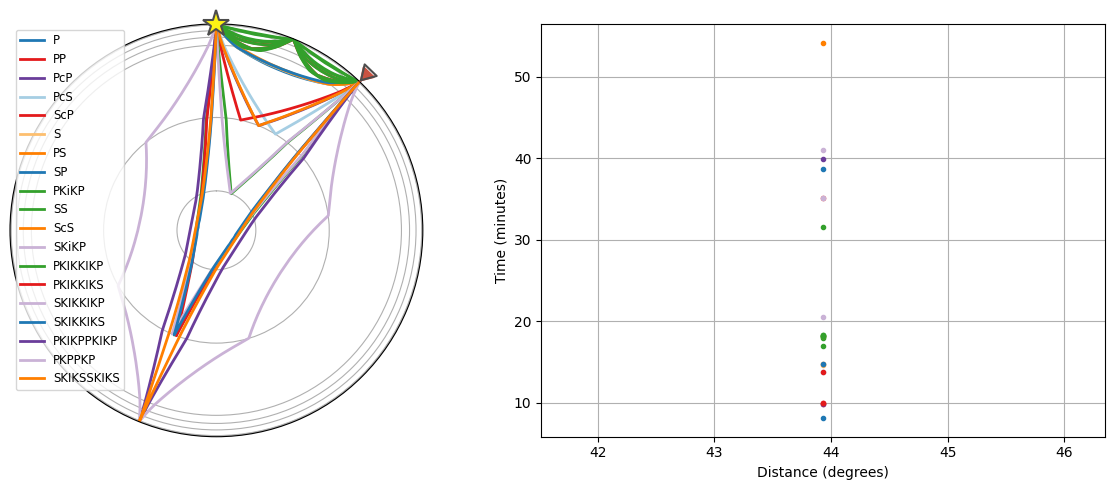

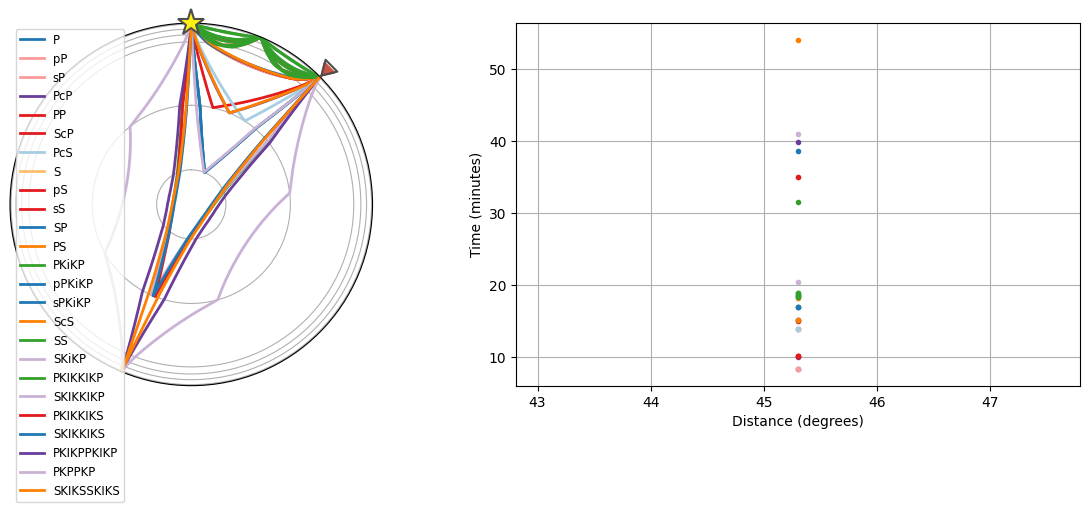

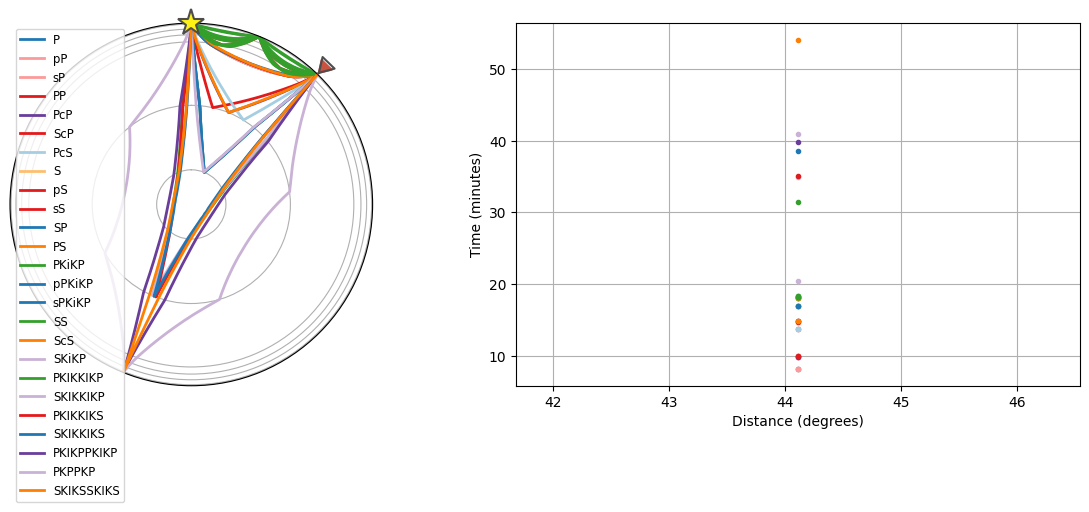

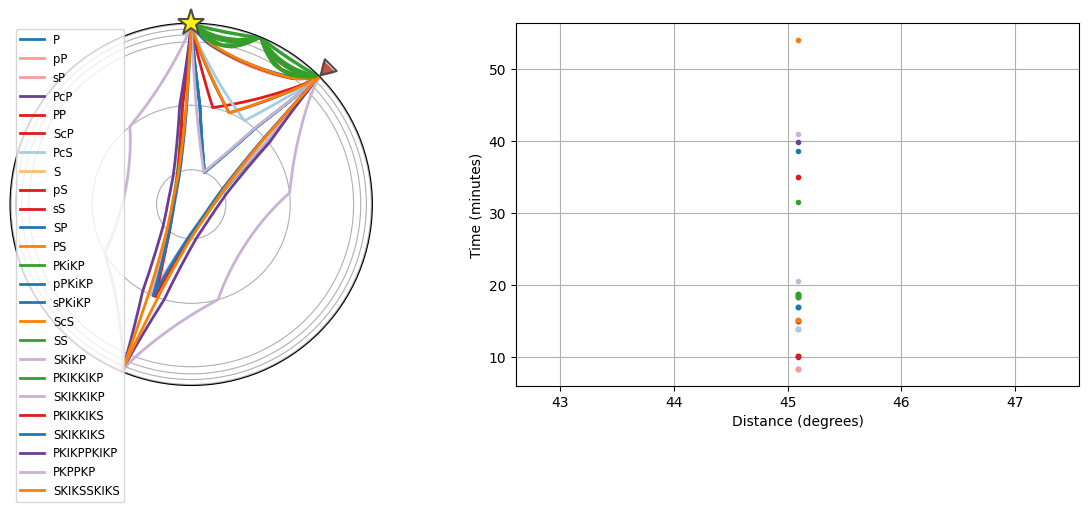

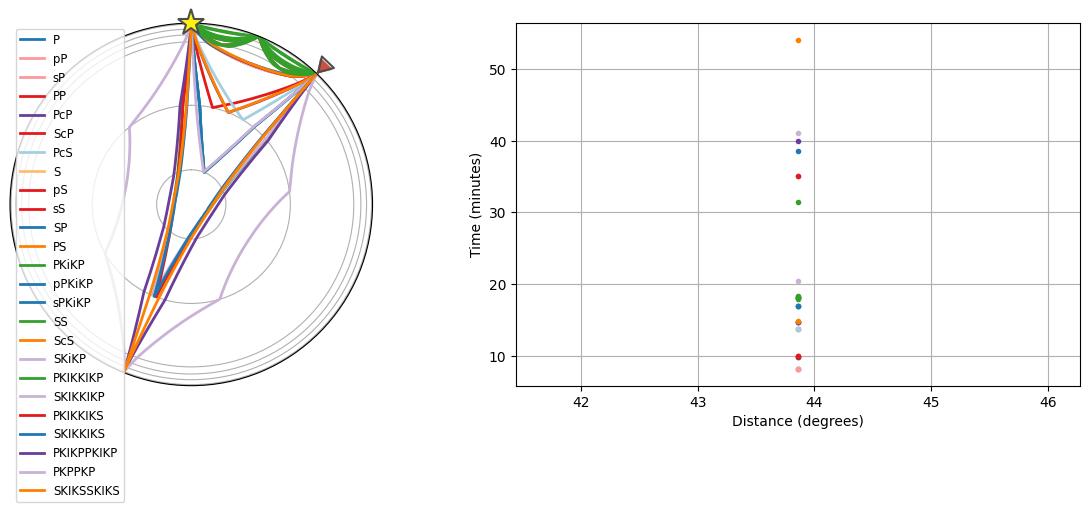

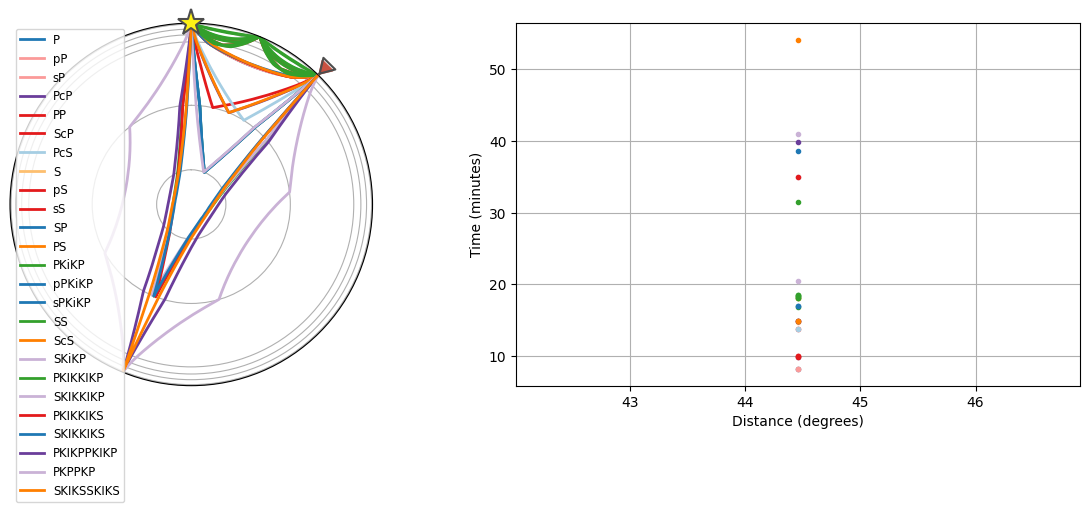

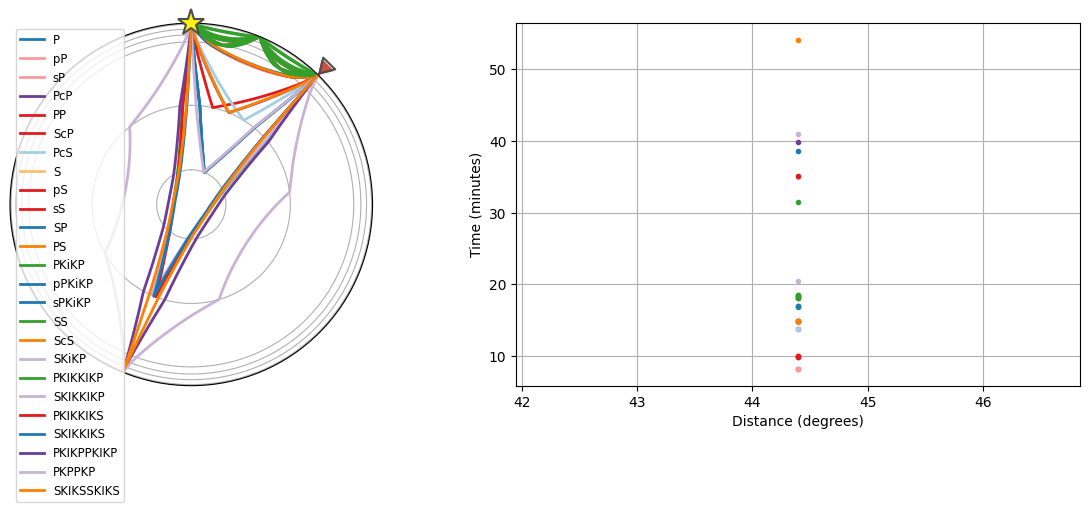

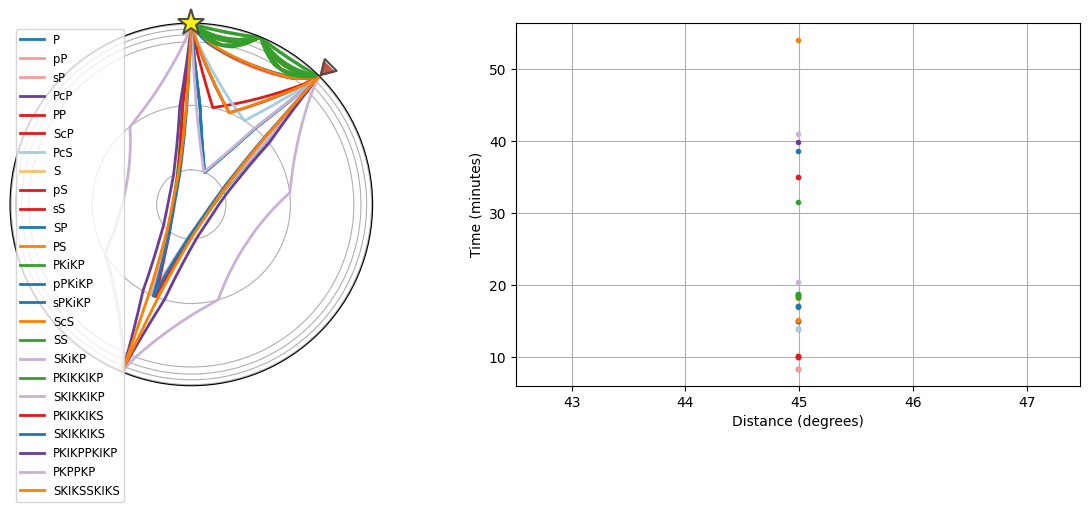

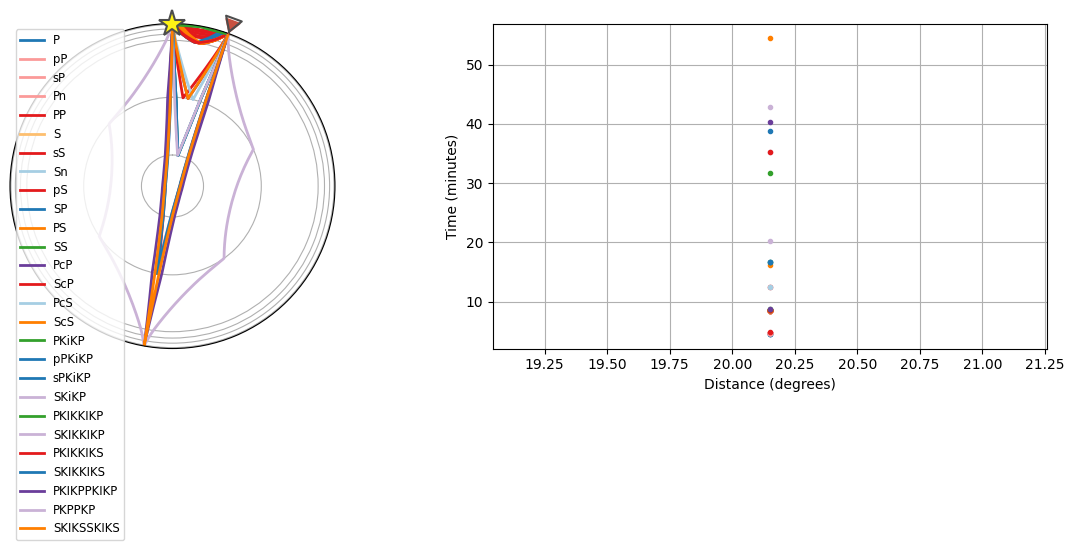

                                              event_id       phase  \
258  Chile-Bolivia Border Region2026-10-09T10:22:08...           P   
259  Chile-Bolivia Border Region2026-10-09T10:22:08...           P   
260  Chile-Bolivia Border Region2026-10-09T10:22:08...           P   
261  Chile-Bolivia Border Region2026-10-09T10:22:08...          pP   
262  Chile-Bolivia Border Region2026-10-09T10:22:08...          sP   
..                                                 ...         ...   
22                   Panama2026-10-09T23:12:38.857356Z    PKIKKIKS   
23                   Panama2026-10-09T23:12:38.857356Z    SKIKKIKS   
24                   Panama2026-10-09T23:12:38.857356Z  PKIKPPKIKP   
25                   Panama2026-10-09T23:12:38.857356Z      PKPPKP   
26                   Panama2026-10-09T23:12:38.857356Z  SKIKSSKIKS   

    takeoff_angle frequency incidente_angle  ray_parameter  travel_time  \
258       34.6444   Unknown        34.58228     623.467324   274.319728   
259     3

In [ ]:
event_data, time_data = analise_catalog(events, catalog, plotting=True)

print(time_data)
print("-------------------------------------------------------------------")
print(event_data)

## <a id='toc1_3_'></a>[Conclusão](#toc0_)

Agora temos tudo que é necessário para calcular a influência de cada onda e então induzir os modelos.